# TrueTone: MUStARD++ final project

**PID-02 | Bennett University, Greater Noida | Instructor: Dr. Saurabh Kumar Srivastava**

Manas Sharma (S24CSEU2420), Raghav Vats (S24CSEU1665), Vaibhav Singh (S24CSEU1668), Sumit Bhati (S24CSEU2870).

## What we built

A text-and-speech sarcasm classifier. Its final weights are fitted on all **1,202 MUStARD++ targets: 601 sarcastic and 601 non-sarcastic**. The original 690-target MUStARD dataset is the comparison baseline. Encoders are frozen; the trained classifier is logistic regression. The final study does not use a gated network, video frames or dialogue context.

## How to review this notebook

Read the explanations, feature functions, training implementation and saved result tables in order. **Run All uses review mode by default:** it reads committed results and skips downloads and expensive training. Set `RETRAIN = True` in the next cell to rebuild the full experiment. Install `requirements-ui.txt` with Python 3.12 and run from the repository root.

The displayed tables and graphs come from saved evaluation files, not invented outputs. Their measured values describe held-out predictions. The final serving refit is separate from evaluation. [Source and deliverables](https://github.com/raghavvxts/TrueTone).


In [1]:
import os, sys, subprocess, json
from pathlib import Path
import numpy as np, pandas as pd, torch, soundfile as sf, librosa
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification, AutoFeatureExtractor, AutoModelForAudioClassification
RETRAIN = False  # Set True only to rebuild datasets/features/evaluation.
ROOT = Path.cwd()
assert (ROOT / 'inference.py').exists(), 'Run from the TrueTone repository root.'
os.environ.setdefault('TRUETONE_DIR', str(ROOT / 'truetone'))
os.environ.setdefault('HF_HOME', str(ROOT / 'truetone/hf'))
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
CACHE = ROOT / 'truetone/pp'
CACHE.mkdir(parents=True, exist_ok=True)
CACHE_KEY = 'live'
def run(script):
    if RETRAIN:
        subprocess.run([sys.executable, str(ROOT / script)], cwd=ROOT, check=True)
    else:
        print(f'Review mode: skipped {script}; using committed evaluation results.')

/Users/raghav/Desktop/TrueTone/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Frozen feature functions

The functions below are the actual definitions used by the local app through a checked AST signature. Defining them does not download weights; calling them does. **Do not change them without regenerating features and models.**

| Input block | Dimensions | Meaning |
|---|---:|---|
| RoBERTa-large text embedding | 1,024 | Target wording |
| Text sentiment | 3 | Negative, neutral, positive probabilities |
| WavLM-large embedding | 2,048 | Mean and standard deviation of middle speech layers |
| Prosody | 58 | Pitch, energy, pauses, spectra and speaking-rate statistics |
| Frozen speech emotion | 4 | Neutral, happy, angry, sad probabilities |
| Mismatch | 6 | Text/voice valence and their differences/product/polarity flip |

Each block is standardized using training data, clipped to [-5, 5], and divided by the square root of its dimensionality before concatenation. Text + speech uses all blocks; Speech reference uses speech embedding, prosody and speech emotion. Speaking-rate features use transcript word counts, so Speech reference is not completely text-independent.

The sarcasm pipeline does not receive ground-truth emotion annotations as input. Its speech-emotion features come from the frozen encoder. A separate experimental nine-emotion head exists in supporting code; it does not replace these features.


In [2]:
@torch.no_grad()
def embed_text(texts, name, pair=None, bs=32, max_len=256):
    tok = AutoTokenizer.from_pretrained(name)
    m = AutoModel.from_pretrained(name).to(DEVICE).eval()
    if DEVICE == 'cuda':
        m = m.half()
    out = []
    for i in tqdm(range(0, len(texts), bs), desc=f'embed {name}'):
        a = texts[i:i + bs]
        b = pair[i:i + bs] if pair is not None else None
        enc = tok(a, b, padding=True, truncation='only_second' if b is not None else True, max_length=max_len, return_tensors='pt').to(DEVICE)
        h = m(**enc).last_hidden_state.float()
        mask = enc['attention_mask'].unsqueeze(-1).float()
        out.append(((h * mask).sum(1) / mask.sum(1)).cpu().numpy())
    del m
    torch.cuda.empty_cache()
    return np.concatenate(out).astype(np.float32)

@torch.no_grad()
def text_sentiment(texts, name, bs=64):
    tok = AutoTokenizer.from_pretrained(name)
    m = AutoModelForSequenceClassification.from_pretrained(name).to(DEVICE).eval()
    id2l = {int(k): v.lower() for k, v in m.config.id2label.items()}
    print('text-sentiment labels:', id2l)
    find = lambda pre, dflt: next((i for i, l in id2l.items() if l.startswith(pre)), dflt)
    order = [find('neg', 0), find('neu', 1), find('pos', 2)]
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i + bs], padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)
        out.append(torch.softmax(m(**enc).logits.float(), -1)[:, order].cpu().numpy())
    del m
    torch.cuda.empty_cache()
    return np.concatenate(out).astype(np.float32)

def load_wav(p, max_s=30):
    y, sr = sf.read(p, dtype='float32')
    if y.ndim > 1:
        y = y.mean(1)
    assert sr == 16000
    y = y[:sr * max_s]
    return np.pad(y, (0, max(0, 8000 - len(y))))

@torch.no_grad()
def wavlm_embed(paths, name):
    fe = AutoFeatureExtractor.from_pretrained(name)
    m = AutoModel.from_pretrained(name).to(DEVICE).eval()
    out = []
    for p in tqdm(paths, desc=f'embed {name}'):
        x = fe(load_wav(p), sampling_rate=16000, return_tensors='pt')['input_values'].to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):
            hs = m(x, output_hidden_states=True).hidden_states
        hs = torch.stack(hs, 0).float()[:, 0]
        L = hs.shape[0] - 1
        mid = hs[L // 3:2 * L // 3 + 1].mean(0)
        out.append(torch.cat([mid.mean(0), mid.std(0)]).cpu().numpy())
    del m
    torch.cuda.empty_cache()
    return np.nan_to_num(np.stack(out)).astype(np.float32)

@torch.no_grad()
def speech_emotion(paths, name):
    fe = AutoFeatureExtractor.from_pretrained(name)
    m = AutoModelForAudioClassification.from_pretrained(name).to(DEVICE).eval()
    labels = [m.config.id2label[i] for i in range(m.config.num_labels)]
    out = []
    for p in tqdm(paths, desc=f'emotion {name}'):
        x = fe(load_wav(p), sampling_rate=16000, return_tensors='pt')['input_values'].to(DEVICE)
        out.append(torch.softmax(m(x).logits.float(), -1)[0].cpu().numpy())
    del m
    torch.cuda.empty_cache()
    json.dump(labels, open(CACHE / f'emo_labels_{CACHE_KEY}.json', 'w'))
    return np.stack(out).astype(np.float32)

def prosody_feats(path, n_words, sr=16000, hop=256, frame=1024):
    y, _ = librosa.load(path, sr=sr, mono=True)
    y = y[:sr * 30]
    if len(y) < sr // 4:
        y = np.pad(y, (0, sr // 4 - len(y)))
    dur = len(y) / sr
    F = {}
    f0, vflag, _ = librosa.pyin(y, fmin=65, fmax=500, sr=sr, frame_length=frame, hop_length=hop)
    idx = np.where(~np.isnan(f0))[0]
    v = f0[idx]
    F['f0_voiced_frac'] = len(idx) / max(len(f0), 1)
    if len(v) >= 5:
        lf = np.log2(v)
        t = idx * hop / sr
        F.update(f0_mean=v.mean(), f0_p10=np.percentile(v, 10), f0_p90=np.percentile(v, 90), f0_std_st=12 * lf.std(), f0_range_st=12 * (np.percentile(lf, 95) - np.percentile(lf, 5)), f0_slope_st_s=12 * np.polyfit(t, lf, 1)[0], jitter=float(np.mean(np.abs(np.diff(v))[np.diff(idx) == 1] / v[:-1][np.diff(idx) == 1])) if np.any(np.diff(idx) == 1) else 0.0)
    else:
        F.update(f0_mean=0, f0_p10=0, f0_p90=0, f0_std_st=0, f0_range_st=0, f0_slope_st_s=0, jitter=0)
    rms = librosa.feature.rms(y=y, frame_length=frame, hop_length=hop)[0]
    db = 20 * np.log10(rms + 1e-06)
    tt = np.arange(len(db)) * hop / sr
    F.update(rms_db_mean=db.mean(), rms_db_std=db.std(), rms_db_max=db.max(), rms_dyn_range=np.percentile(db, 90) - np.percentile(db, 10), rms_slope=np.polyfit(tt, db, 1)[0] if len(db) > 2 else 0, shimmer=np.mean(np.abs(np.diff(db))))
    iv = librosa.effects.split(y, top_db=30, frame_length=frame, hop_length=hop)
    speech_dur = sum((e - s for s, e in iv)) / sr
    gaps = np.array([(iv[i + 1][0] - iv[i][1]) / sr for i in range(len(iv) - 1)]) if len(iv) > 1 else np.array([])
    gaps = gaps[gaps >= 0.15]
    onsets = librosa.onset.onset_detect(y=y, sr=sr, hop_length=hop, units='time')
    F.update(duration=dur, speech_dur=speech_dur, speech_ratio=speech_dur / dur, n_pauses=len(gaps), pause_total=gaps.sum() if len(gaps) else 0, pause_ratio=gaps.sum() / dur if len(gaps) else 0, pause_mean=gaps.mean() if len(gaps) else 0, pause_max=gaps.max() if len(gaps) else 0, onset_rate=len(onsets) / dur, onset_rate_speech=len(onsets) / max(speech_dur, 0.1), words_per_sec=n_words / dur, words_per_sec_speech=n_words / max(speech_dur, 0.1), articulation_rate=n_words / max(speech_dur, 0.1))
    S = np.abs(librosa.stft(y, n_fft=frame, hop_length=hop))
    cen = librosa.feature.spectral_centroid(S=S, sr=sr)[0]
    F.update(cent_mean=cen.mean(), cent_std=cen.std(), flat_mean=librosa.feature.spectral_flatness(S=S).mean(), zcr_mean=librosa.feature.zero_crossing_rate(y, frame_length=frame, hop_length=hop).mean(), rolloff_mean=librosa.feature.spectral_rolloff(S=S, sr=sr).mean())
    mf = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=frame, hop_length=hop)
    for k in range(13):
        F[f'mfcc{k}_mean'] = mf[k].mean()
        F[f'mfcc{k}_std'] = mf[k].std()
    return {k: float(np.nan_to_num(x)) for k, x in F.items()}

def emo_valence(lbl):
    l = lbl.lower()
    if any((k in l for k in ('hap', 'joy', 'surpris', 'exc'))):
        return 1.0
    if any((k in l for k in ('ang', 'sad', 'fear', 'disg', 'fru'))):
        return -1.0
    return 0.0

## 2. Download and validate the datasets

The next step checks official MUStARD++ annotations and archive hashes. It runs only with `RETRAIN = True`. Raw videos, audio and caches remain under ignored local folders. Review mode does not need these downloads.


In [3]:
run('experiment/download.py')

Review mode: skipped experiment/download.py; using committed evaluation results.


## 3. Prepare the MUStARD baseline

The original 690-target corpus is retained to make a controlled comparison. It is not the active app dataset. Original text/audio features are preserved; the archived notebook is historical evidence, not a second final notebook to present.


In [4]:
run('experiment/prepare_baseline.py')

Review mode: skipped experiment/prepare_baseline.py; using committed evaluation results.


## 4. Prepare all 1,202 MUStARD++ targets

There are 688 IDs shared with MUStARD, 514 added targets, and two original IDs absent from the expanded release. Six shared transcripts changed. The same MUStARD++ test features are used for both training conditions. Audio is 16 kHz mono; target audio and text are used without video/context features.


In [5]:
run('experiment/prepare.py')

Review mode: skipped experiment/prepare.py; using committed evaluation results.


### Training implementation

This read-only cell prints the actual helper function. Its inputs are separate training/test feature dictionaries, labels, groups, selected blocks and a seed. The scaler learns only from outer-training rows. `class_weight='balanced'` sets class weights; the reported test scores are not computed here from training predictions.

In [6]:
# Read-only view of the exact train-fold implementation used by compare.py.
import inspect
from experiment.compare import fit_predict
print(inspect.getsource(fit_predict))

def fit_predict(train, y, groups, test, blocks, config, seed):
    xs, xt = [], []
    for block in blocks:
        sc = StandardScaler().fit(train[block])
        weight = 1/np.sqrt(train[block].shape[1])
        xs.append(np.clip(sc.transform(train[block]), -5, 5)*weight)
        xt.append(np.clip(sc.transform(test[block]), -5, 5)*weight)
    # Keep repeated utterances together even during C selection.
    splits = list(StratifiedGroupKFold(3, shuffle=True, random_state=seed).split(np.zeros(len(y)), y, groups))
    for tr, te in splits:
        assert not set(groups[tr]) & set(groups[te])
    classifier = LogisticRegressionCV(Cs=config['lr_Cs'], cv=splits, scoring='neg_log_loss',
                                      class_weight='balanced', max_iter=3000)
    classifier.fit(np.hstack(xs), y)
    return classifier.predict_proba(np.hstack(xt))[:, list(classifier.classes_).index(1)]



## 5. Train, evaluate and refit

`experiment/compare.py` runs the actual comparison. The code is kept in a helper so the app and notebook do not carry conflicting copies.

- Three repeats (seeds 42-44) of five stratified grouped outer folds on the same 688 shared targets.
- Shared IDs, identical normalized text and identical decoded audio are grouped across corpora. Held-out groups are excluded from both training conditions.
- Compare MUStARD, full MUStARD++, and size-matched MUStARD++ training with the same feature/classifier settings.
- Train-fold scaling precedes a three-fold grouped choice of C by log loss. The outer test data are excluded. Scaling is reused inside the inner folds, so preprocessing is not fully nested.
- Average each target's three out-of-fold probabilities, threshold at 0.5, and compute accuracy, precision, recall, F1 and macro F1.
- Bootstrap paired F1 differences over groups (2,000 samples). Test unseen shows separately.
- Finally refit the serving bundle on all 1,202 MUStARD++ targets. That refit is for the app, not a new accuracy evaluation.

**What was optimized?** Class-balanced logistic regression, maximum 3,000 iterations, C grid `[0.1, 0.5, 2, 10, 50, 300, 1000]`. Both final serving modes selected C=2.0. No encoder fine-tuning or epoch-wise neural-network training curve is claimed.


In [7]:
run('experiment/compare.py')

Review mode: skipped experiment/compare.py; using committed evaluation results.


## 6. Measured results

These tables read committed CSVs. They contain averaged held-out predictions, not training accuracy. Text + speech reaches **F1 0.7608 / accuracy 0.7515** with MUStARD++, compared with **F1 0.7435 / accuracy 0.7413** for MUStARD. F1 and accuracy are different metrics.

The F1 difference is +0.0173, with a paired 95% interval of [-0.0073, +0.0420]. The interval includes zero. We finalize MUStARD++ as the project dataset while retaining this uncertainty; we do not claim conclusive superiority or live-microphone accuracy. Size-matched Text + speech F1 is 0.7435. Small held-out shows have strongly skewed labels, so their F1 needs caution.


In [8]:
display(pd.read_csv(ROOT / 'results/mustardpp/summary.csv'))
display(pd.read_csv(ROOT / 'results/mustardpp/paired_bootstrap.csv'))
held = pd.read_csv(ROOT / 'results/mustardpp/held_out_show.csv')
display(held[held['mode'] == 'Text + speech'].reset_index(drop=True))

,training,mode,n_test,f1,macro_f1,accuracy,precision,recall,mean_fold_f1,std_fold_f1
0,MUStARD,Speech reference,688,0.723647,0.717906,0.718023,0.709497,0.738372,0.722657,0.036595
1,MUStARD,Text + speech,688,0.743516,0.741259,0.741279,0.737143,0.750000,0.741647,0.040639
2,MUStARD,Text only,688,0.660000,0.653964,0.654070,0.648876,0.671512,0.658810,0.032647
3,MUStARD++,Speech reference,688,0.723703,0.713284,0.713663,0.699187,0.750000,0.735084,0.045975
4,MUStARD++,Text + speech,688,0.760839,0.751070,0.751453,0.733154,0.790698,0.758152,0.034895
5,MUStARD++,Text only,688,0.685552,0.677105,0.677326,0.668508,0.703488,0.692413,0.037346
6,MUStARD++ size-matched,Speech reference,688,0.732044,0.717249,0.718023,0.697368,0.770349,0.718279,0.044218
7,MUStARD++ size-matched,Text + speech,688,0.743484,0.727229,0.728198,0.703896,0.787791,0.732984,0.037997
8,MUStARD++ size-matched,Text only,688,0.706371,0.691106,0.691860,0.674603,0.741279,0.672922,0.036513


,mode,comparison,delta_f1,ci_low,ci_high
0,Text only,MUStARD++ minus MUStARD,0.025552,-0.003863,0.057554
1,Text only,MUStARD++ size-matched minus MUStARD,0.046371,0.019499,0.074622
2,Speech reference,MUStARD++ minus MUStARD,0.000056,-0.026314,0.026217
3,Speech reference,MUStARD++ size-matched minus MUStARD,0.008397,-0.016489,0.034101
4,Text + speech,MUStARD++ minus MUStARD,0.017323,-0.007315,0.041983
5,Text + speech,MUStARD++ size-matched minus MUStARD,-0.000032,-0.027433,0.025327


,show,training,mode,n_train,n_test,n_positive,f1,macro_f1,accuracy,precision,recall
0,BBT,MUStARD,Text + speech,405,716,360,0.703495,0.610463,0.632682,0.592030,0.866667
1,BBT,MUStARD++,Text + speech,481,716,360,0.699401,0.639483,0.649441,0.614737,0.811111
2,FRIENDS,MUStARD,Text + speech,333,354,151,0.612903,0.655698,0.661017,0.597484,0.629139
3,FRIENDS,MUStARD++,Text + speech,844,354,151,0.721854,0.757479,0.762712,0.721854,0.721854
4,GOLDENGIRLS,MUStARD,Text + speech,650,40,39,0.947368,0.473684,0.900000,0.972973,0.923077
5,GOLDENGIRLS,MUStARD++,Text + speech,1162,40,39,0.961039,0.480519,0.925000,0.973684,0.948718
6,SARCASMOHOLICS,MUStARD,Text + speech,674,14,14,0.352941,0.176471,0.214286,1.000000,0.214286
7,SARCASMOHOLICS,MUStARD++,Text + speech,1186,14,14,0.352941,0.176471,0.214286,1.000000,0.214286
8,SV,MUStARD,Text + speech,686,78,37,0.352941,0.519328,0.576923,0.642857,0.243243
9,SV,MUStARD++,Text + speech,1120,78,37,0.531250,0.602582,0.615385,0.629630,0.459459


## 7. Graphs from the same saved results

The figures below are pooled F1, shared-target confusion counts and paired confidence intervals. They are evaluation graphs, not invented epoch-loss curves. Rebuild sources: `scripts/paper_figures.py` and `results/paper/`.

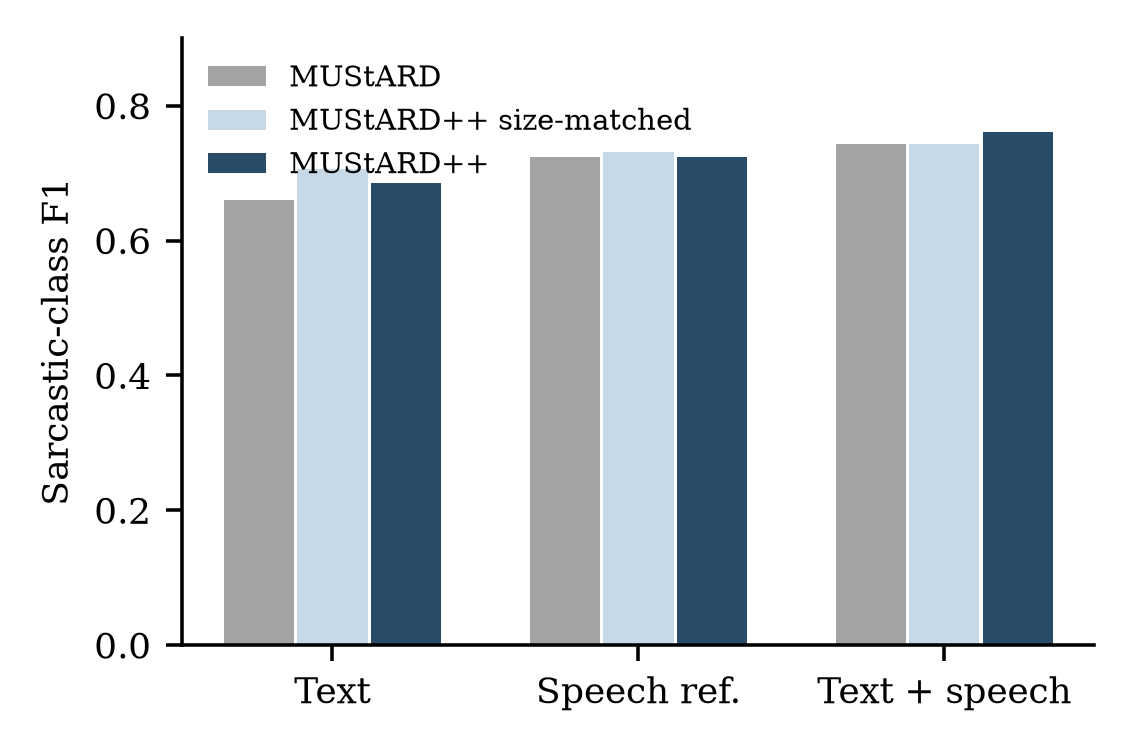

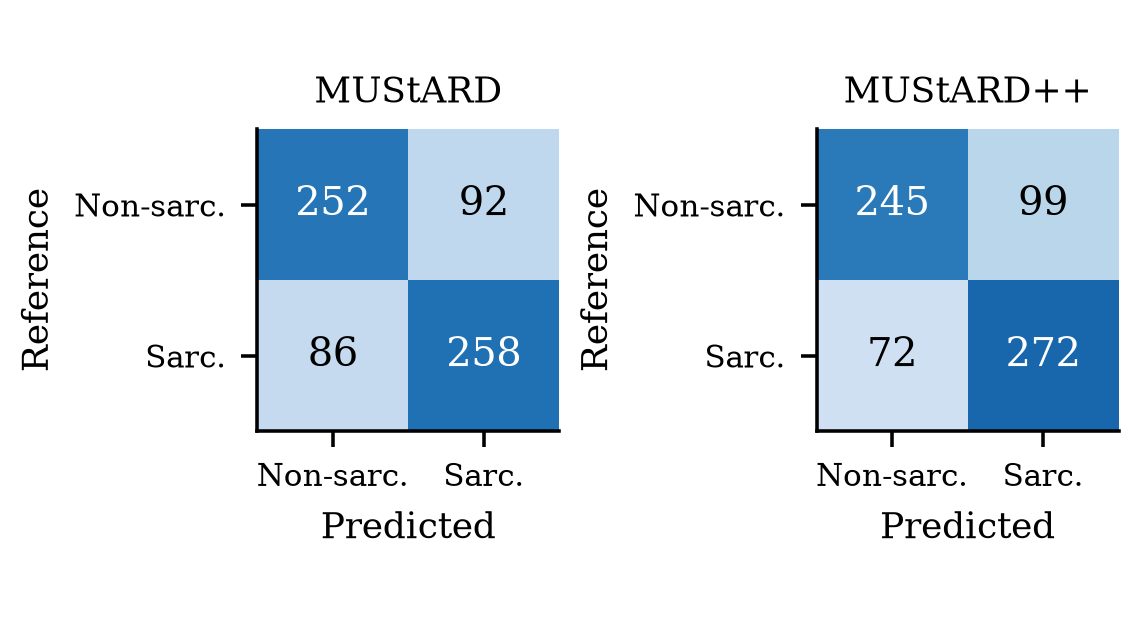

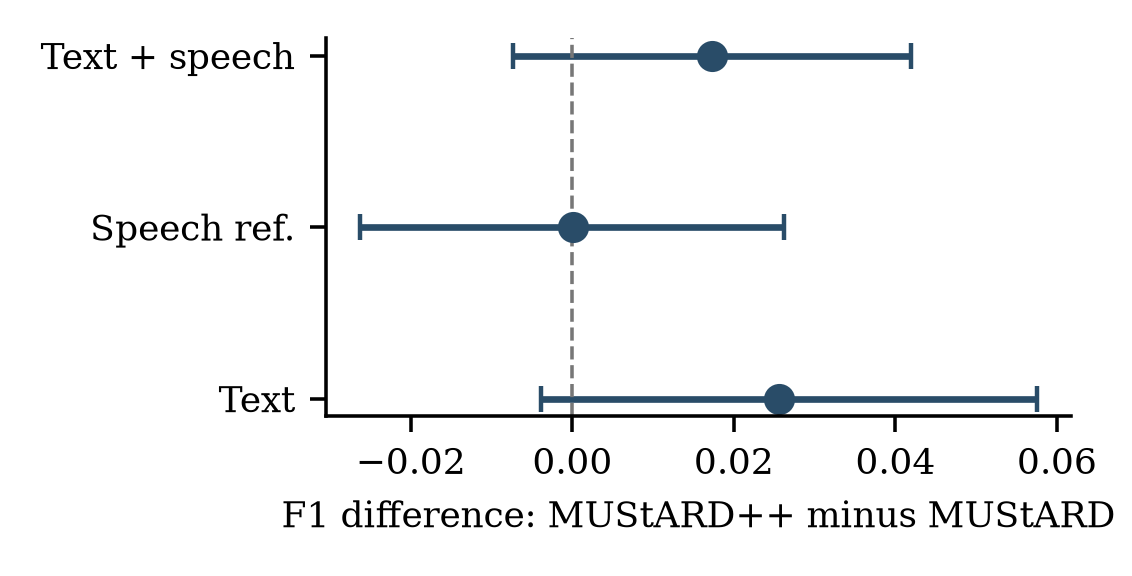

In [9]:
from IPython.display import Image, display
for name in ['f1_comparison.png', 'confusion_matrices.png', 'paired_intervals.png']:
    display(Image(filename=str(ROOT / 'results/paper' / name), width=560))

## 8. Scope and limitations

**Why MUStARD++?** It is the required final dataset and includes 1,202 targets with richer annotations. Its observed multimodal gain over our original baseline is small and uncertain.

**What is trained?** Logistic-regression heads. RoBERTa, sentiment, WavLM and the original four-class emotion encoder remain frozen.

**How is leakage handled?** Group duplicate IDs, text and decoded audio across both corpora, then exclude test groups from both training conditions. Related episodes/speakers may still remain; this is a limitation. Inner preprocessing is not fully nested.

**Why can live recordings be wrong?** TV speech differs from ordinary microphone recordings, ASR may mishear words, and sarcasm can need missing context. A near-100% emotion score is not verified correctness.

**Is the new emotion head final?** No. The separate nine-class surface-emotion experiment has held-out-show accuracy 0.310 and macro F1 0.146; majority accuracy is 0.364. It remains an explicit experimental option. No independently labelled microphone adaptation study has been run.

**Where is the actual final model?** `models/truetone_lr.joblib`, checked against `models/manifest.json`. The original 690-target weights remain under `models/baseline/`.

**Are demo checks accuracy results?** No. Dataset demos were seen during the final refit. Generated uploads test processing and ASR; they do not have validated human emotion or sarcasm labels.
